In [52]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.model_selection import train_test_split
import numpy as np

In [53]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [54]:
# 데이터 전처리 완료
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight, random_state=1)
train_data


array([21. , 16.2, 24. , 43. , 28.7, 24.6, 39. , 43.5, 25. , 28. , 21.3,
       23. , 40. , 27.3, 22. , 42. , 27.5, 23.5, 17.4, 22. , 26.5, 25.6,
       40. , 36.5, 22. , 44. , 22.5, 24. , 18.7, 19. , 43. , 13.7, 22. ,
        8.4, 22. , 18. , 21. , 20. , 19.6, 21. , 37. , 32.8])

In [55]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data[:3]

array([[21. ],
       [16.2],
       [24. ]])

In [56]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)

# 데이터 에측
predict = lr.predict(test_data)
print('무게예측:',predict)

# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('정답률:',score,score2)

# 기울기,y절편 = LinearRegression() 사용할때 나타남
print('기울기:',lr.coef_)
# ※ 무게 = 기울기 × 길이 + 절편
print('y절편:',lr.intercept_)

무게예측: [772.10648708 -83.74503482 772.10648708 183.70856577 362.01096617
 362.01096617 451.16216637 629.46456676 807.76696716 700.78552692
 807.76696716 190.84066179 611.63432672 665.12504684]
정답률: 0.921150162087582 0.8801532075437282
기울기: [35.66048008]
y절편: -618.6522360150107


In [57]:
# KNeighborsRegressor l:50 - w:1000로 예측함
# 50cm 농어 예측 50 - 1164
# 100cm 농어 예측 100 - 2947

predict2 = lr.predict([[100]])
predict2

array([2947.39577192])

입력길이: 5.0
예측무게: [-440.34983562]


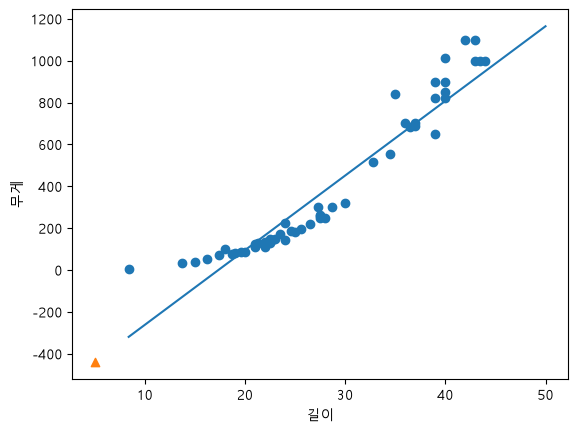

In [68]:
# 길이 입력받아, 무게를 예측하고 ,산점도 그래프에 표시하시오.
# 농어길리를 입력하세요 예)52
# 예측무게 :1230
# 산점도 그래프에 표시
# 선 그래프도 함께 표시
l = input('길이입력:')
l = float(l)
w = lr.predict([[l]])
# ※ 짧은 길이는 음수가 나옴 → 직선의 한계 (다항회귀로 해결)
print('입력길이:',l)
print('예측무게:',w)

plt.scatter(perch_length,perch_weight)
plt.scatter(l,w,marker='^')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_]) # 선그래프
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

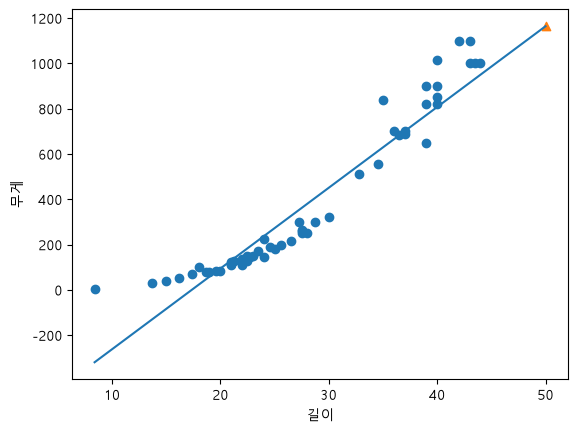

In [65]:
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(50,1164,marker='^')
# plt.scatter(100,2947,marker='D')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_]) # 선그래프
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

기울기: [35.66048008]
